In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_csv("../../datasets/a_regression_car_price/cleaned_car_prices.csv")

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Price"])
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

print(X_train.shape, X_test.shape)

(4209, 12) (1804, 12)


## Numerical

### Imputation

In [22]:
from sklearn.impute import SimpleImputer

num_cols = ["Kilometers_Driven", "Mileage", "Engine", "Power", "Seats", "Car_Age"]
imputer = SimpleImputer(strategy="median")

X_train_num = imputer.fit_transform(X_train[num_cols])
X_test_num = imputer.transform(X_test[num_cols])

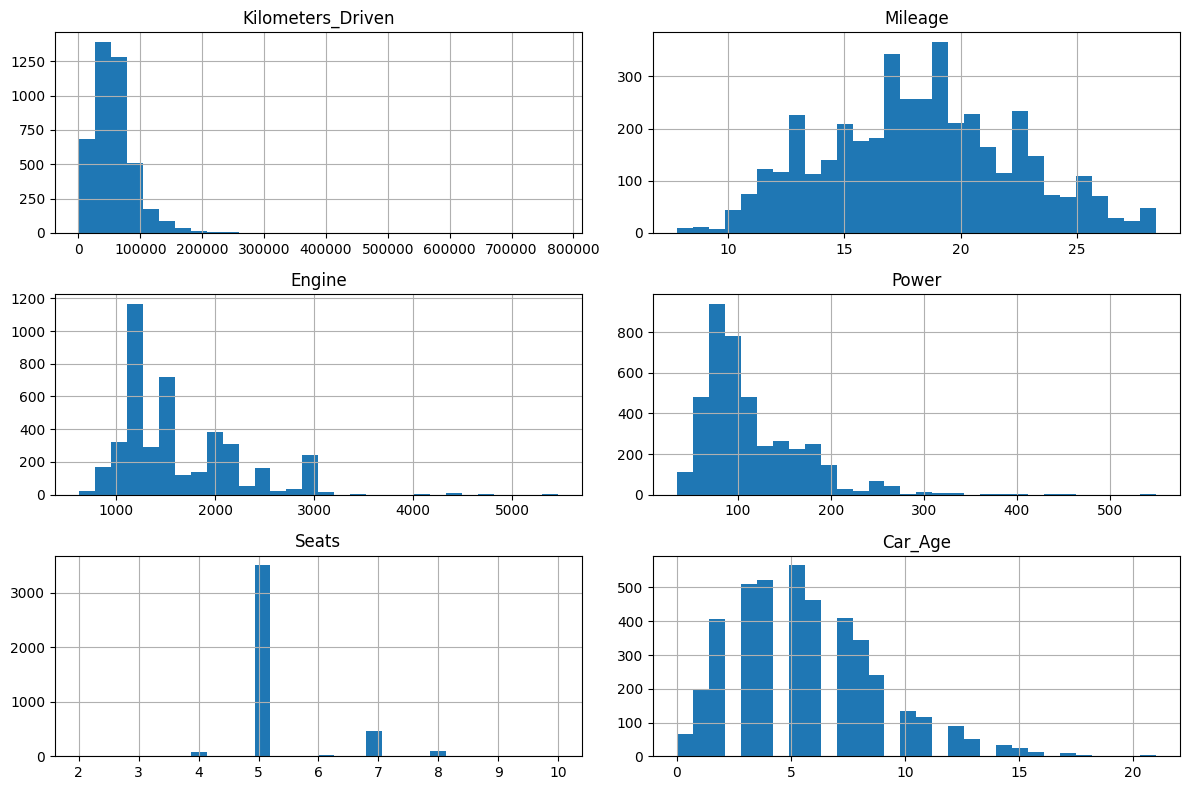

Features Skewness:
 Kilometers_Driven    4.137504
Seats                2.054041
Power                1.703120
Engine               1.266436
Car_Age              0.839284
Mileage              0.106187
dtype: float64

Target (Price) Skewness: 2.919956339155663


In [23]:
X_train.select_dtypes(include="number").hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

print("Features Skewness:\n", X_train.select_dtypes(include="number").skew().sort_values(ascending=False))
print("\nTarget (Price) Skewness:", y_train.skew())

### Outliers Detection & Scaling 

In [24]:
# Detecting Outliers by IQR in X_train_num
def detect_outliers_iqr(series, factor=1.5):
    Q1 = np.nanpercentile(series, 25)
    Q3 = np.nanpercentile(series, 75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    outliers = series[(series < lower) | (series > upper)]
    return len(outliers), lower, upper

In [25]:
for col in num_cols:
    iqr_count, iqr_low, iqr_high = detect_outliers_iqr(X_train[col], factor=1.5)
    
    print(f"{col} IQR   ->  {iqr_count} outliers | Bounds: [{iqr_low:.1f} to {iqr_high:.1f}]")

Kilometers_Driven IQR   ->  149 outliers | Bounds: [-23729.0 to 130215.0]
Mileage IQR   ->  0 outliers | Bounds: [6.5 to 29.9]
Engine IQR   ->  36 outliers | Bounds: [6.0 to 3182.0]
Power IQR   ->  159 outliers | Bounds: [-16.6 to 230.9]
Seats IQR   ->  669 outliers | Bounds: [5.0 to 5.0]
Car_Age IQR   ->  33 outliers | Bounds: [-4.5 to 15.5]


In [26]:
from sklearn.preprocessing import RobustScaler

robust = RobustScaler()

X_train_robust = robust.fit_transform(X_train_num)
X_test_robust = robust.transform(X_test_num)

### Transformation

In [27]:
from sklearn.preprocessing import FunctionTransformer
log_transformer = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

# num_cols: Kilometers_Driven(0), Mileage(1), Engine(2), Power(3), Seats(4), Car_Age(5)
log_indices = [0, 2, 3]
X_train_logged = X_train_num.copy()
X_test_logged = X_test_num.copy()

X_train_logged[:, log_indices] = log_transformer.fit_transform(X_train_num[:, log_indices])
X_test_logged[:, log_indices] = log_transformer.transform(X_test_num[:, log_indices])

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

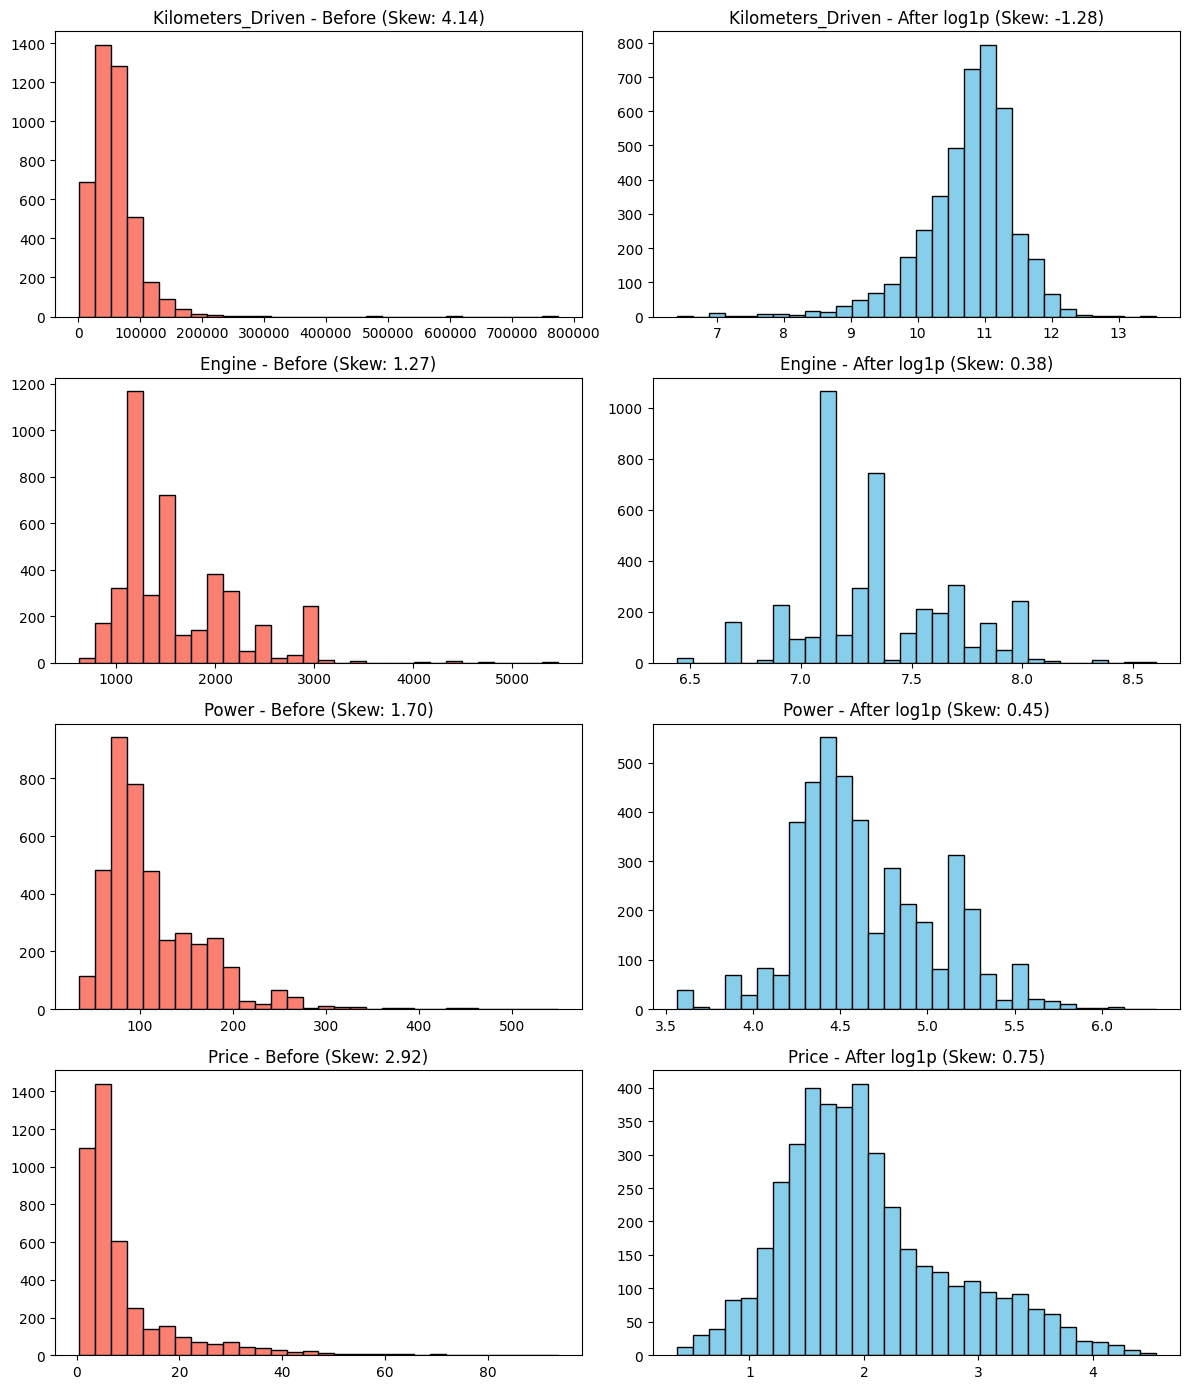

In [28]:
df_after = pd.DataFrame(X_train_logged, columns=num_cols)

cols_to_plot = ["Kilometers_Driven", "Engine", "Power", "Price"]
before_data = [X_train["Kilometers_Driven"], X_train["Engine"], X_train["Power"], y_train]
after_data  = [df_after["Kilometers_Driven"], df_after["Engine"], df_after["Power"], y_train_log]

fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for i, col in enumerate(cols_to_plot):
    # Before column on the left (column 0)
    axes[i, 0].hist(before_data[i], bins=30, color="salmon", edgecolor="black")
    axes[i, 0].set_title(f"{col} - Before (Skew: {before_data[i].skew():.2f})")
    
    # After column on the right (column 1)
    axes[i, 1].hist(after_data[i], bins=30, color="skyblue", edgecolor="black")
    axes[i, 1].set_title(f"{col} - After log1p (Skew: {after_data[i].skew():.2f})")

plt.tight_layout()
plt.show()

## Categorical

### Imputation

In [29]:
from sklearn.impute import SimpleImputer

cat_cols = ['Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Brand', 'Model']


cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

### Encoding

In [30]:
df_train_cat = pd.DataFrame(X_train_cat, columns=cat_cols)
df_test_cat  = pd.DataFrame(X_test_cat, columns=cat_cols)

In [31]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_cols = ["Owner_Type"]
# Fourth & Above=0, Third=1, Second=2, First=3
owner_order = ["Fourth & Above", "Third", "Second", "First"]

ord_enc = OrdinalEncoder(
    categories=[owner_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

train_ord = ord_enc.fit_transform(df_train_cat[ordinal_cols])
test_ord  = ord_enc.transform(df_test_cat[ordinal_cols])

print("Ordinal shape:", train_ord.shape)

Ordinal shape: (4209, 1)


In [32]:
from sklearn.preprocessing import MinMaxScaler

ord_scaler = MinMaxScaler()

train_ord_scaled = ord_scaler.fit_transform(train_ord)
test_ord_scaled  = ord_scaler.transform(test_ord)

print("Scaled Ordinal min & max:", train_ord_scaled.min(), "to", train_ord_scaled.max())

Scaled Ordinal min & max: 0.0 to 1.0


In [33]:
from sklearn.preprocessing import OneHotEncoder

onehot_cols = ["Location", "Fuel_Type", "Transmission"]

ohe_enc = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
    drop="if_binary"
)

train_ohe = ohe_enc.fit_transform(df_train_cat[onehot_cols])
test_ohe  = ohe_enc.transform(df_test_cat[onehot_cols])

print("OneHot shape:", train_ohe.shape)

OneHot shape: (4209, 16)


In [34]:
%pip install category_encoders

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
from category_encoders import BinaryEncoder

binary_cols = [col for col in ["Brand", "Model"] if col in cat_cols]

bin_enc = BinaryEncoder()

train_bin = bin_enc.fit_transform(df_train_cat[binary_cols])
test_bin  = bin_enc.transform(df_test_cat[binary_cols])

print("Binary shape:", train_bin.shape)

Binary shape: (4209, 13)


## Pipeline

In [36]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, FunctionTransformer, OrdinalEncoder, OneHotEncoder, MinMaxScaler
from category_encoders import BinaryEncoder

num_log_cols   = ["Kilometers_Driven", "Engine", "Power"]
num_other_cols = ["Mileage", "Seats", "Car_Age"]
ordinal_cols   = ["Owner_Type"]
onehot_cols    = ["Location", "Fuel_Type", "Transmission"]
binary_cols    = [col for col in ["Brand", "Model"] if col in X_train.columns]


num_log_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log",     FunctionTransformer(np.log1p)),
    ("scaler",  RobustScaler())
])

num_other_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  RobustScaler())
])

owner_order = ["Fourth & Above", "Third", "Second", "First"]
ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[owner_order], handle_unknown="use_encoded_value", unknown_value=-1)),
    ("scaler",  MinMaxScaler())
])

onehot_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="if_binary"))
])

binary_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", BinaryEncoder())
])

preprocessor = ColumnTransformer([
    ("num_log",   num_log_pipe,   num_log_cols),
    ("num_other", num_other_pipe, num_other_cols),
    ("ordinal",   ordinal_pipe,   ordinal_cols),
    ("onehot",    onehot_pipe,    onehot_cols),
    ("binary",    binary_pipe,    binary_cols)
])

## Linear Regression (scikit-learn)

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_final, y_train_log)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [39]:
y_train_pred_log = lr_model.predict(X_train_final)
y_test_pred_log = lr_model.predict(X_test_final)

In [40]:
y_train_pred = np.expm1(y_train_pred_log)
y_test_pred = np.expm1(y_test_pred_log)

y_train_actual = np.expm1(y_train_log)
y_test_actual = np.expm1(y_test_log)

In [41]:
def evaluate_model(y_true, y_pred, dataset_name):

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"{dataset_name} Results")
    print("-" * 30)
    print(f"MAE  : {mae:.2f}")
    print(f"MSE  : {mse:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R2   : {r2:.4f}")

In [42]:
evaluate_model(y_train_actual, y_train_pred, "Training Set")
evaluate_model(y_test_actual, y_test_pred, "Testing Set")

Training Set Results
------------------------------
MAE  : 2.14
MSE  : 21.53
RMSE : 4.64
R2   : 0.8131
Testing Set Results
------------------------------
MAE  : 2.20
MSE  : 21.39
RMSE : 4.62
R2   : 0.8325


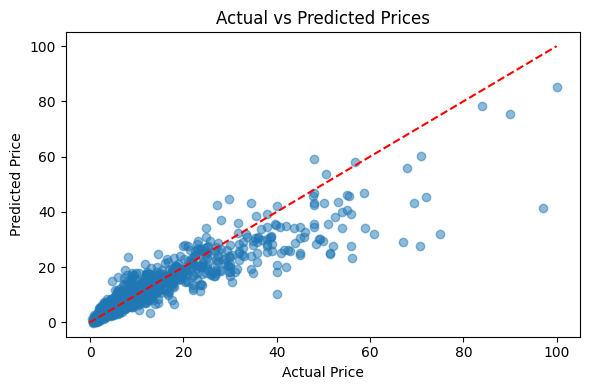

In [46]:
plt.figure(figsize=(6, 4))

plt.scatter(y_test_actual, y_test_pred, alpha=0.5)

min_val = min(y_test_actual.min(), y_test_pred.min())
max_val = max(y_test_actual.max(), y_test_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

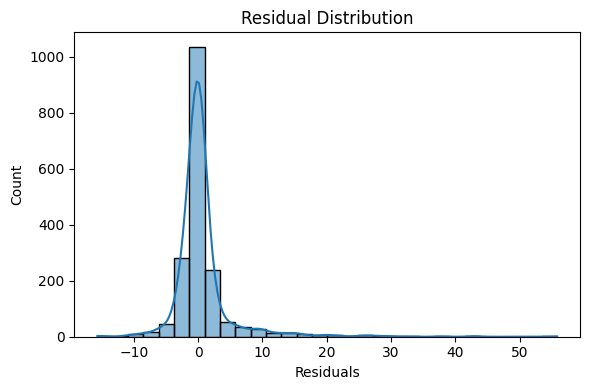

In [47]:
plt.figure(figsize=(6, 4))

sns.histplot(residuals, bins=30, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution")

plt.tight_layout()
plt.show()

## Linear Regression (From Scratch)